# Exercise: Parallel Monte Carlo (Threads)

**Note: You should use multiple Julia threads for this exercise!**

In [1]:
using Base.Threads
@assert Threads.nthreads() > 1
Threads.nthreads()

4

Calculate the value of $\pi$ through parallel direct Monte Carlo.

A unit circle is inscribed inside a unit square with side length 2 (from -1 to 1). The area of the circle is $\pi$, the area of the square is 4, and the ratio is $\pi/4$. This means that, if you throw $N$ darts randomly at the square, approximately $M=N\pi/4$ of those darts will land inside the unit circle.

Throw darts randomly at a unit square and count how many of them ($M$) landed inside of a unit circle. Approximate $\pi \approx 4M/N$. Visualization:

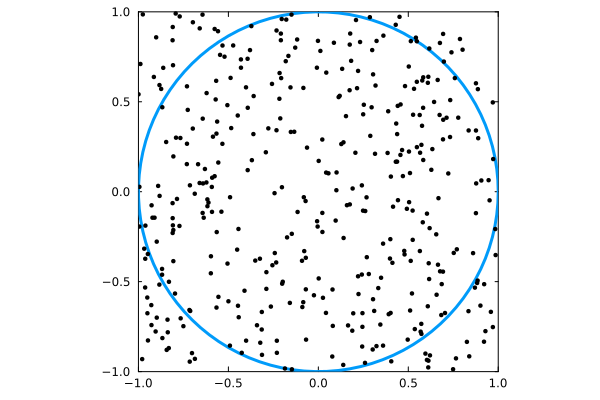

In [6]:
using Plots
using Distributions

# plot circle
circlepts = Plots.partialcircle(0, 2π, 100)
plot(circlepts, aspect_ratio=:equal, xlims=(-1, 1), ylims=(-1, 1), legend=false, lw=3, grid=false, frame=:box)

# plot darts
N = 400
d = Uniform(-1, 1)
scatter!(rand(d, N), rand(d, N), ms=2.5, color=:black)

### Basic Julia Implementation

In [72]:
function compute_pi(N)
    M = 0 # number of darts that landed in the circle
    for i in 1:N
        if sqrt(rand()^2 + rand()^2) < 1.0
            M += 1
        end
    end
    return 4 * M / N
end

compute_pi (generic function with 1 method)

In [73]:
compute_pi(10_000_000)

3.141552

In [92]:
@btime compute_pi(10_000_000) samples=5 evals=2

  34.909 ms (0 allocations: 0 bytes)


3.1416668

### Tasks

1. Based on `compute_pi`, write a parallel version `compute_pi_parallel(N::Int)` that divides the work into `Threads.nthreads()` parallel tasks. The final estimate for π should be the average of the estimate of each task. 
    1. **Hint:** Be aware of false sharing, that is, make sure that every tasks operates locally and only shares the local result at the end.
    2. **Hint:** You may call the serial `compute_pi` in your code.
    3. **Hint:** If you want, implement two versions, one based on `@tasks` and one using `@spawn`. (Bonus: write one using `tmapreduce` from OhMyThreads).

2. Benchmark and compare the serial and parallel variants.
    1. **Hint:** A reasonable value for $N$ could be `N = 10_000_000`.

In [140]:
using BenchmarkTools
using OhMyThreads: chunks, index_chunks, tmap
using Base.Threads

In [148]:
# TODO...
function compute_pi_parallel(N,nchunks=nthreads())
    Nc = N/nchunks;
    # Mtot = 0.0;
    M_vec = zeros(nchunks,)
    for ii = 1:nchunks
        # Mtot += compute_pi(Nc)
        M_vec[ii] = compute_pi(Nc)
    end
    return mean(M_vec)
    # return mean(compute_pi(Nc) for i in 1:nchunks)
end
@btime compute_pi_parallel(10_000_000) samples=5 evals=2

  44.054 ms (2 allocations: 96 bytes)


3.1415615999999997

In [65]:
# VERY VERY BAD IMPLEMENTATION
function check_cirlce(v1,v2)
        if sqrt(v1^2 + v2^2) < 1.0
            vM = 1
        else
            vM = 0
        end
end
function sum_map_spawn(data; ntasks=nthreads())
    ts = map(chunks(data, n=ntasks)) do chunk_elements
        @spawn sum(chunk_elements)
    end
    return sum(fetch.(ts))
end
function compute_pi_parallel_bad(N)
data=check_cirlce.( rand(N,),rand(N,));
return sum_map_spawn(data; ntasks=nthreads())*4/N
end

compute_pi_parallel_bad (generic function with 1 method)

In [66]:
@btime compute_pi_parallel_bad(10_000_000) samples=5 evals=2

  111.522 ms (51 allocations: 228.89 MiB)


3.1416424

3. Write a function `compute_pi_multiple(Ns::Vector{Int})` which takes in a collection of values for $N$ (`Ns`) and **in serial** computes $\pi$ for all these values. The function should be **entirely serial** and based on `compute_pi`. Benchmark and compare to the previous variants.

In [128]:
some_Ns = [10, 100, 1000, 10_000, 100_000, 1_000_000, 2_000_000, 3_000_000, 4_000_000]

# TODO...
function compute_pi_multiple(Ns::Vector{Int})
    Ms = zeros(length(some_Ns))
    for ii = 1:length(some_Ns)
        Ms[ii] = compute_pi(some_Ns[ii])
    end
    return Ms
end
@btime compute_pi_multiple(some_Ns) samples=5 evals=2
# @btime compute_pi_multiple(some_Ns) samples=5 evals=2

  35.003 ms (28 allocations: 704 bytes)


9-element Vector{Float64}:
 3.6
 3.04
 3.06
 3.154
 3.13704
 3.139308
 3.140974
 3.1412546666666668
 3.142904

4. Write a function `compute_pi_multiple_parallel(Ns::Vector{Int})` which takes in a collection of values for $N$ (`Ns`) and **in parallel** computes $\pi$ for all these values. The function should still be based on the serial `compute_pi`. Benchmark and compare to the previous variants.
    1. **Hint:** You shouldn't use `@tasks` with default configuration (`ntasks=nthreads()`) here, because the workload is non-uniform. Either use `@set ntasks=length(Ns)` or write a version using `@spawn`. (Bonus: write a variant using `tmap` from OhMyThreads.)

5. Calculate $\pi$ estimates for the following $N$ values: `Ns = ceil.(Int, exp10.(range(1, stop=8, length=50)))`. Plot $\pi$ vs $N$ on a semi-log plot.

In [143]:
some_Ns = [10, 100, 1000, 10_000, 100_000, 1_000_000, 2_000_000, 3_000_000, 4_000_000]

# TODO...
function compute_pi_multiple_parallel(some_Ns::Vector{Int})
    Ms = tmap(compute_pi,some_Ns)
    return Ms
end
@btime compute_pi_multiple_parallel(some_Ns) samples=5 evals=2
# @btime compute_pi_multiple_parallel($some_Ns) samples=5 evals=2

  25.345 ms (55 allocations: 2.72 KiB)


9-element Vector{Float64}:
 2.8
 3.32
 3.136
 3.128
 3.13788
 3.143676
 3.142186
 3.1415746666666666
 3.141392

In [154]:
Ns

50-element Vector{Int64}:
        10
        14
        20
        27
        38
        52
        72
       100
       139
       194
       269
       373
       518
         ⋮
   2682696
   3727594
   5179475
   7196857
  10000000
  13894955
  19306978
  26826958
  37275938
  51794747
  71968568
 100000000

In [151]:
# N values (nothing todo here)
Ns = ceil.(Int, exp10.(range(1, stop=8, length=50)));

In [152]:
# Important: the resulting pi estimates should be stored in a variable named: pis
# TODO...
pis = compute_pi_multiple_parallel(Ns)

50-element Vector{Float64}:
 2.4
 2.5714285714285716
 3.2
 3.111111111111111
 3.0526315789473686
 3.230769230769231
 2.7222222222222223
 2.92
 3.568345323741007
 3.134020618556701
 3.16728624535316
 3.099195710455764
 3.088803088803089
 ⋮
 3.1420406933920204
 3.1414182982374155
 3.142352458502068
 3.141032258943036
 3.1417224
 3.142089484996533
 3.141837940665805
 3.141355348601209
 3.141669996339193
 3.141804862952608
 3.141431798392876
 3.14140708

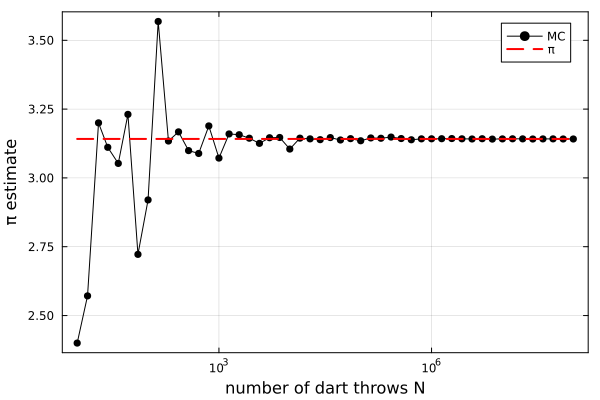

In [153]:
# Plotting (nothing todo here)
plot(Ns, pis, color=:black, marker=:circle, lw=1, label="MC", xscale=:log10, frame=:box)
plot!(x -> π, label="π", xscale=:log10, linestyle=:dash, color=:red, lw=2)
ylabel!("π estimate")
xlabel!("number of dart throws N")

6. **Bonus:** Try to write a function `compute_pi_multiple_nested_parallel(Ns::Vector{Int})` which computes $\pi$ for all given $N$ values using nested multithreading: Both the outer computation ("for each N in Ns") as well as the inner computation ("compute pi for a given N") should be parallelized. Benchmark and compare to the previous variants.

In [ ]:
some_Ns = [10, 100, 1000, 10_000, 100_000, 1_000_000, 2_000_000, 3_000_000, 4_000_000]

# TODO...

# @btime compute_pi_multiple_nested_parallel($some_Ns) samples=5 evals=2

# from above, for comparison
# @btime compute_pi_multiple_parallel($some_Ns) samples=5 evals=2